# RiceVision AI
## Notebook 04: Model Training (EfficientNet-B0)

### Objective

Train an EfficientNet-B0 model using transfer learning for rice leaf disease classification.

Tasks:
- Load DataLoaders
- Build model
- Freeze backbone
- Train model
- Save best model
- Plot training curves

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(PROJECT_ROOT)

D:\Jupyter\CropDisease


In [2]:
from src.config import *
from src.dataset import get_dataloaders
from src.model import (
    build_model,
    freeze_backbone,
    print_model_summary
)
from src.trainer import Trainer
from src.utils import (
    set_seed,
    plot_training_curves,
    load_checkpoint
)

In [3]:
set_seed(SEED)

print("Device :", DEVICE)

Device : cpu


In [4]:
train_loader, val_loader, test_loader = get_dataloaders()

print(f"Train Batches      : {len(train_loader)}")
print(f"Validation Batches : {len(val_loader)}")
print(f"Test Batches       : {len(test_loader)}")

Train Batches      : 130
Validation Batches : 28
Test Batches       : 28


In [5]:
model = build_model()

print_model_summary(model)

Model : efficientnet_b0
Total Parameters      : 4,012,672
Trainable Parameters  : 4,012,672


In [6]:
model = freeze_backbone(model)

print_model_summary(model)

Model : efficientnet_b0
Total Parameters      : 4,012,672
Trainable Parameters  : 5,124


In [7]:
trainer = Trainer(model)

In [8]:
history = trainer.fit(
    train_loader,
    val_loader
)

Epoch 1/20


Train Loss : 0.6820
Val Loss   : 0.3077
Train Acc  : 0.7620
Val Acc    : 0.9169
Epoch 2/20


Train Loss : 0.4066
Val Loss   : 0.2043
Train Acc  : 0.8690
Val Acc    : 0.9539
Epoch 3/20


Train Loss : 0.3353
Val Loss   : 0.1664
Train Acc  : 0.8899
Val Acc    : 0.9629
Epoch 4/20


Train Loss : 0.3004
Val Loss   : 0.1296
Train Acc  : 0.9005
Val Acc    : 0.9753
Epoch 5/20


Train Loss : 0.2681
Val Loss   : 0.1091
Train Acc  : 0.9118
Val Acc    : 0.9753
Epoch 6/20


... (11 outputs left out)

Train Loss : 0.1902
Val Loss   : 0.0451
Train Acc  : 0.9302
Val Acc    : 0.9944
Epoch 18/20


Train Loss : 0.1892
Val Loss   : 0.0414
Train Acc  : 0.9321
Val Acc    : 0.9966
Epoch 19/20


Train Loss : 0.2002
Val Loss   : 0.0424
Train Acc  : 0.9273
Val Acc    : 0.9944
Epoch 20/20


Train Loss : 0.1892
Val Loss   : 0.0445
Train Acc  : 0.9289
Val Acc    : 0.9955


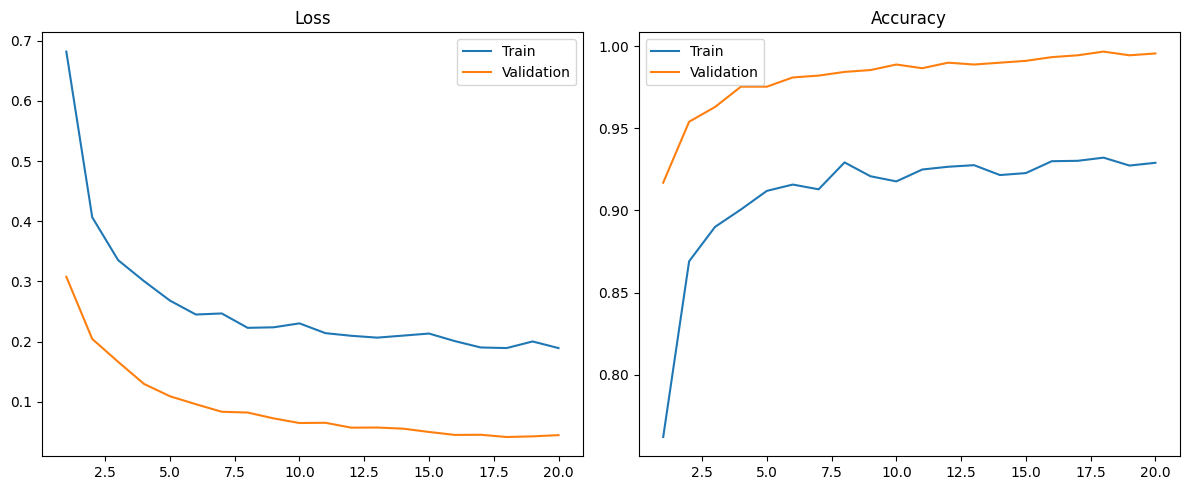

In [11]:
plot_training_curves(history)

In [12]:
best_model = load_checkpoint(
    model,
    MODEL_PATH / "best_model.pth",
    DEVICE
)

# Notebook Summary

## Completed

- Loaded the dataset
- Initialized EfficientNet-B0
- Applied transfer learning
- Trained the classifier
- Saved the best-performing model
- Generated training curves

## Output

- best_model.pth
- Training history
- Accuracy curves
- Loss curves